## Gradient Boosting

## Load Data

In [3]:
import sys
from pathlib import Path

project_root = Path.cwd()
while not (project_root / "src").is_dir():
    if project_root == project_root.parent:
        raise FileNotFoundError("Could not locate the project root")
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data.load_data import load_nsl_kdd

train, test = load_nsl_kdd()
train.head()

True


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class,y
0,0.0,tcp,ftp_data,SF,491.0,0.0,0,0.0,0.0,0.0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,0
1,0.0,udp,other,SF,146.0,0.0,0,0.0,0.0,0.0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,0
2,0.0,tcp,private,S0,0.0,0.0,0,0.0,0.0,0.0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly,1
3,0.0,tcp,http,SF,232.0,8153.0,0,0.0,0.0,0.0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,0
4,0.0,tcp,http,SF,199.0,420.0,0,0.0,0.0,0.0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,0


## Preprocessing Data

In [4]:
from src.data.preprocess import prep

# Preprocess the training data
target = train["y"]
preprocessor = prep()
train_preprocessed = preprocessor.fit_transform(train)

#print(target)
print(train_preprocessed)

[[-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 ...
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]]


In [ ]:
#Making sure the correct version of xgboost is installed
import xgboost as xgb 
print("XGBoost version: ", xgb.__version__)

XGBoost version:  3.4.1


## Train Model

In [10]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split


#Splitting data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(train_preprocessed, target, test_size=0.2, random_state=42, stratify=target)
# Encode string labels to integers (a requirement for XGBoost for classification)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.fit_transform(y_test)


#Initialize the XGBoost classifier
# It uses very similar parameters to scikit-learn's GradientBoostingClassifier, (but with some differences, can adjust based on needs)
xgb_model = xgb.XGBClassifier(
    #hyperparameters for the XGBoost model; Question why are these specific hyperparameters chosen? (Test different values to see their impactz)
    objective='binary:logistic',  # For binary classification (default is 'binary:logistic')
    n_estimators=500,  # Number of boosting rounds (default is 100)
    learning_rate=0.7,  # Step size shrinkage (default is 0.1)
    max_depth=3,  # Maximum depth of a tree (default is 3)
    subsample=0.8,  # Subsample ratio of the training instance (default is 0.8)
    colsample_bytree=0.8,  # Subsample ratio of columns when constructing each tree (default is 0.8)
    random_state=42,  # For reproducibility (defult is 42)
    eval_metric='logloss'  # Evaluation metric for binary classification (default is 'logloss')
)

#Train the model
print("Training the XGBoost model...")
xgb_model.fit(X_train, y_train_encoded)

# 2. Get predictions (Hard predictions vs. Probabilities)
y_pred = xgb_model.predict(X_test)  # 0 or 1 for the Confusion Matrix
y_prob = xgb_model.predict_proba(X_test)[
    :, 1
]

#Making predictions on the test set
print("Making predictions...")
predictions = xgb_model.predict(X_test)
print("Predictions: ", predictions)


Training the XGBoost model...
Making predictions...
Predictions:  [1 0 1 ... 0 1 1]


## Visualizing Model

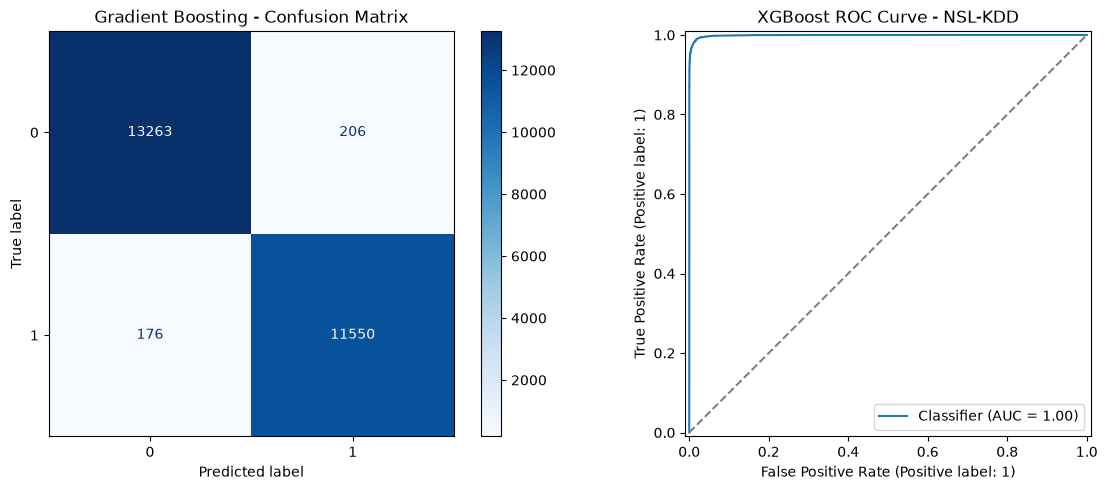

In [18]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import train_test_split

#Create a figure and axis for the CMD
fig, axes = plt.subplots(1,2, figsize=(12,5))

#Generate the confusion matrix plot from the trained XGBoost estimator
#ConfusionMatrixDisplay.from_estimator(
  #  xgb_model,
   # X_test,
    #y_test_encoded,
    #display_labels=label_encoder.classes_,
    #cmap=plt.cm.Blues,
    #ax=ax,
    #ticks_rotation=45
#)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap="Blues")
axes[0].set_title("Gradient Boosting - Confusion Matrix")

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
# Add the dashed diagonal chance baseline
axes[1].plot(
    [0, 1], [0, 1], linestyle="--", color="gray", label="Chance (AUC = 0.5)"
)
axes[1].set_title("XGBoost ROC Curve - NSL-KDD")
plt.tight_layout()
plt.show()